In [1]:
%matplotlib ipympl

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import reduction_utils.wavelength_calibration as wc
import pickle
import reduction_utils.wavelength_binning as wb
import reduction_utils.cosmic_removal as c

/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:667: SyntaxWarning: invalid escape sequence '\A'
  plt.xlabel('Wavelength ($\AA$)')
/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:739: SyntaxWarning: invalid escape sequence '\A'
  plt.ylabel('Wavelength ($\AA$)')
/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:744: SyntaxWarning: invalid escape sequence '\A'
  plt.ylabel('Wavelength ($\AA$)')
/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:775: SyntaxWarning: invalid escape sequence '\A'
  plt.ylabel('Wavelength ($\AA$)')
/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:780: SyntaxWarning: invalid escape sequence '\A'
  plt.ylabel('Wavelength ($\AA$)')
/data2/ju126/Tiberius/src/reduction_utils/wavelength_calibration.py:1120: SyntaxWarning: invalid escape sequence '\A'
  plt.xlabel("Wavelength ($\AA$)")


In [3]:
import importlib
importlib.reload(c)

<module 'reduction_utils.cosmic_removal' from '/data2/ju126/Tiberius/src/reduction_utils/cosmic_removal.py'>

In [4]:
star = pickle.load(open('../pickled_objects/star1_flux.pickle','rb'))
error = pickle.load(open('../pickled_objects/star1_error.pickle','rb'))

xpos = pickle.load(open('../pickled_objects/x_positions_1.pickle','rb'))
sky = pickle.load(open('../pickled_objects/background_avg_star1.pickle','rb'))

### Cross-correlation

This is performed across the entire spectra, not individual chunks, which of course assumes the shifts do not have a wavelength dependence.

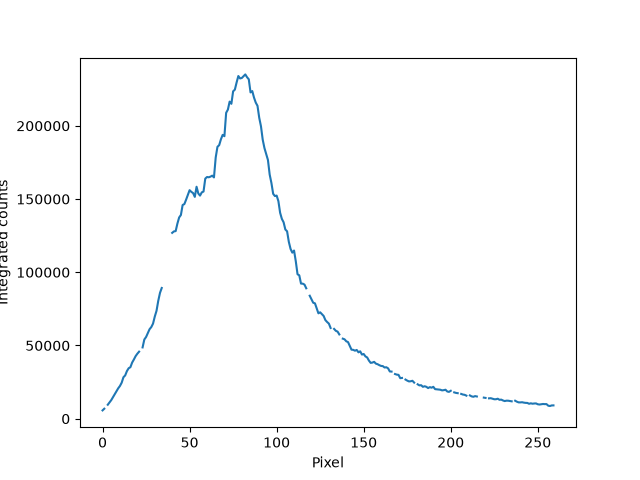

In [5]:
# define the reference spectrum to compare all other spectra with
nframes = len(star)
reference_spectrum = star[0]

plt.figure()
plt.plot(reference_spectrum)
plt.xlabel("Pixel")
plt.ylabel("Integrated counts")
plt.show()

In [ ]:
importlib.reload(wc)

# Define the dictionary of inputs for star 1 that we want to be resampled
input1 = {'xposition':xpos,'sky':sky}

resampled_flux,resampled_error,\
resampled_ancil,star_cc_line_shifts = \
wc.compute_all_shifts_whole_spectrum(reference_spectrum,star,\
                                     error,verbose=True,\
                                  resample=True,ancillary_data=input1)


In [ ]:
plt.figure()
plt.subplot(211)
plt.plot(np.nansum(resampled_flux,axis=1),'k.')
plt.ylabel("Flux")

plt.subplot(212)
plt.plot(star_cc_line_shifts)
plt.xlabel("Frame")
plt.ylabel("Pixel shift")
plt.show()

In [ ]:
xpos /= 10

In [ ]:
plt.figure()
plt.subplot(211)
# have to divide by 10 to account for the oversampling factor
plt.plot(xpos.mean(axis=1)-xpos.mean(),label="RMS = %.3f"%(np.sqrt(np.mean((xpos.mean(axis=1)-xpos.mean())**2))))
plt.legend()
plt.ylabel("X pixel shift")
plt.subplot(212)
plt.plot(star_cc_line_shifts,label="RMS = %.3f"%(np.sqrt(np.mean(star_cc_line_shifts**2))))
plt.legend()
plt.xlabel("Integration")
plt.ylabel("Y pixel shift")
plt.savefig("pixel_shifts.png",bbox_inches="tight",dpi=360)
plt.show()

In [ ]:
pickle.dump(resampled_flux,open('../pickled_objects/star1_flux_resampled.pickle','wb'))
pickle.dump(resampled_error,open('../pickled_objects/star1_error_resampled.pickle','wb'))
pickle.dump(resampled_ancil['xposition'],open('../pickled_objects/xpos1_resampled.pickle','wb'))
pickle.dump(resampled_ancil['sky'],open('../pickled_objects/sky1_resampled.pickle','wb'))
pickle.dump(star_cc_line_shifts,open('../pickled_objects/ypos1.pickle','wb'))